# Lab 8: Data Visualization using Python (Matplotlib & Seaborn)

**Dataset:** [Wine Quality — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality)
(Cortez et al., 2009). 6,497 Portuguese *Vinho Verde* wines (1,599 red, 4,898 white), each described by
11 physicochemical measurements and a sensory **quality** score (0–10) given by wine experts.

**Goal:** explore what separates red from white wine and which chemical properties are associated with higher quality.

Every chart is also exported as a PNG to the `charts/` folder.

## Setup
```bash
python -m venv .venv            # or: conda create --name info5100
.venv\Scripts\activate          # or: conda activate info5100
pip install -r requirements.txt
```

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

def save(fig, name):
    """Export a figure to charts/<name>.png"""
    fig.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")

## Loading the data into Pandas DataFrames
The UCI files are semicolon-separated, one per wine type. We combine them and add a `type` column.

In [2]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")
red["type"] = "red"
white["type"] = "white"

wine = pd.concat([red, white], ignore_index=True)
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [4]:
wine.describe().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00
mean,7.22,0.34,0.32,5.44,0.06,30.53,115.74,0.99,3.22,0.53,10.49,5.82
std,1.30,0.16,0.15,4.76,0.04,17.75,56.52,0.00,0.16,0.15,1.19,0.87
min,3.80,0.08,0.00,0.60,0.01,1.00,6.00,0.99,2.72,0.22,8.00,3.00
25%,6.40,0.23,0.25,1.80,0.04,17.00,77.00,0.99,3.11,0.43,9.50,5.00
50%,7.00,0.29,0.31,3.00,0.05,29.00,118.00,0.99,3.21,0.51,10.30,6.00
75%,7.70,0.40,0.39,8.10,0.06,41.00,156.00,1.00,3.32,0.60,11.30,6.00
max,15.90,1.58,1.66,65.80,0.61,289.00,440.00,1.04,4.01,2.00,14.90,9.00


In [5]:
print("Missing values:", wine.isna().sum().sum())
wine["type"].value_counts()

Missing values: 0


type
white    4898
red      1599
Name: count, dtype: int64

In [6]:
wine.groupby("type")["quality"].value_counts().unstack(fill_value=0)

quality,3,4,5,6,7,8,9
type,,,,,,,
red,10,53,681,638,199,18,0
white,20,163,1457,2198,880,175,5


## 1. Bar Chart — Quality score distribution by wine type (Seaborn)
**Categorical / univariate.** Most wines are rated 5–6; very poor (3) and excellent (9) wines are rare,
so the dataset is heavily imbalanced toward average quality.

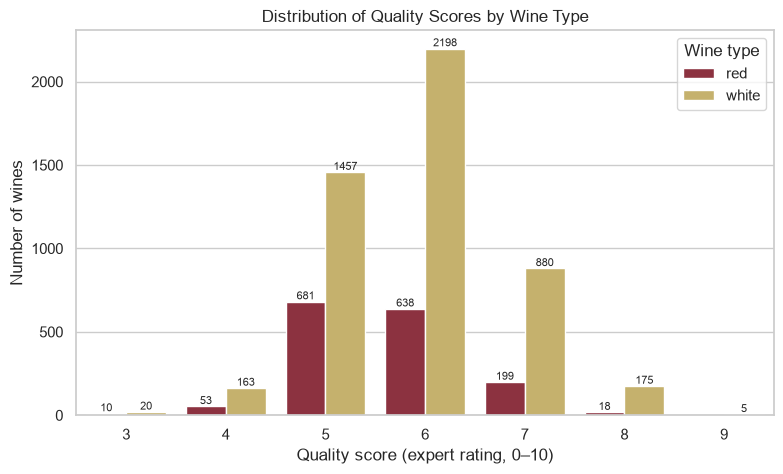

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(data=wine, x="quality", hue="type",
              palette={"red": "#9b2335", "white": "#d4b95e"}, ax=ax)
ax.set_title("Distribution of Quality Scores by Wine Type")
ax.set_xlabel("Quality score (expert rating, 0–10)")
ax.set_ylabel("Number of wines")
ax.legend(title="Wine type")
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
save(fig, "01_quality_distribution_bar")
plt.show()

## 2. Histogram + KDE — Alcohol content by wine type (Seaborn)
**Univariate distribution.** Both types are right-skewed around 9–10% ABV; red and white have very similar alcohol profiles.

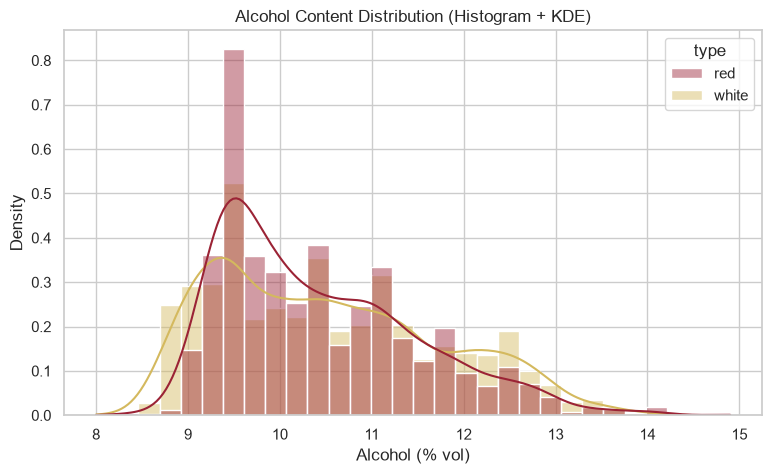

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=wine, x="alcohol", hue="type", kde=True, stat="density",
             common_norm=False, bins=30, alpha=0.45,
             palette={"red": "#9b2335", "white": "#d4b95e"}, ax=ax)
ax.set_title("Alcohol Content Distribution (Histogram + KDE)")
ax.set_xlabel("Alcohol (% vol)")
ax.set_ylabel("Density")
save(fig, "02_alcohol_histogram_kde")
plt.show()

## 3. Box Plot — Alcohol vs. quality (Seaborn)
**Bivariate (categorical vs. numeric).** Median alcohol rises steadily from quality 5 upward —
alcohol is the single strongest predictor of perceived quality.

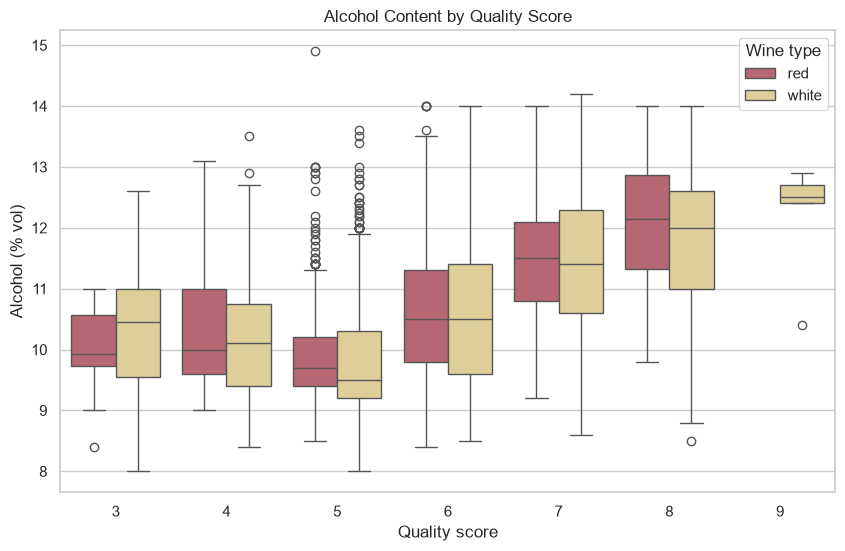

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=wine, x="quality", y="alcohol", hue="type",
            palette={"red": "#c45a6a", "white": "#e8d48f"}, ax=ax)
ax.set_title("Alcohol Content by Quality Score")
ax.set_xlabel("Quality score")
ax.set_ylabel("Alcohol (% vol)")
ax.legend(title="Wine type")
save(fig, "03_alcohol_by_quality_boxplot")
plt.show()

## 4. Scatter Plot — Alcohol vs. volatile acidity, coloured by quality (Matplotlib)
**Multivariate (3 variables).** Higher-quality wines (lighter points) cluster at *high alcohol* and *low volatile acidity*
(volatile acidity gives a vinegar-like taste).

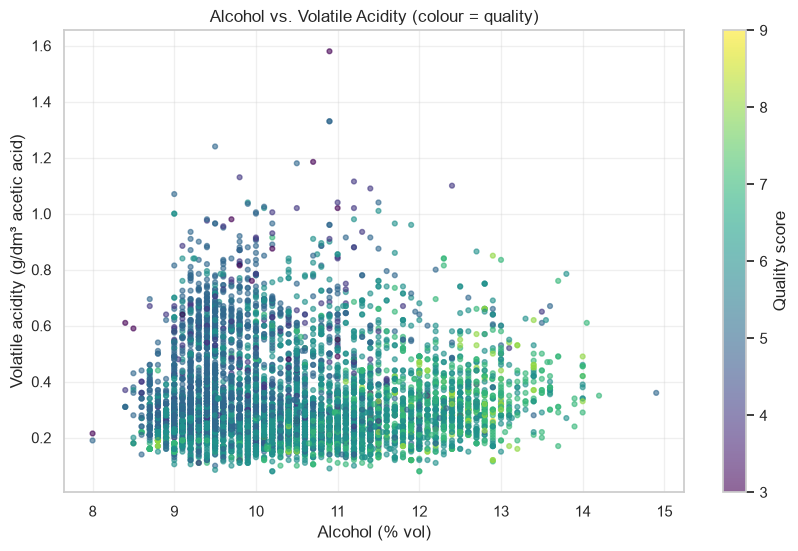

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(wine["alcohol"], wine["volatile acidity"],
                c=wine["quality"], cmap="viridis", s=12, alpha=0.6)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Quality score")
ax.set_title("Alcohol vs. Volatile Acidity (colour = quality)")
ax.set_xlabel("Alcohol (% vol)")
ax.set_ylabel("Volatile acidity (g/dm³ acetic acid)")
ax.grid(True, alpha=0.3)
save(fig, "04_alcohol_vs_volatile_acidity_scatter")
plt.show()

## 5. Correlation Heat Map (Seaborn)
**Multivariate.** Pearson correlation between all numeric features. `alcohol` has the strongest positive correlation
with quality; `density` and `volatile acidity` are negatively correlated. `density` is strongly tied to alcohol and residual sugar.

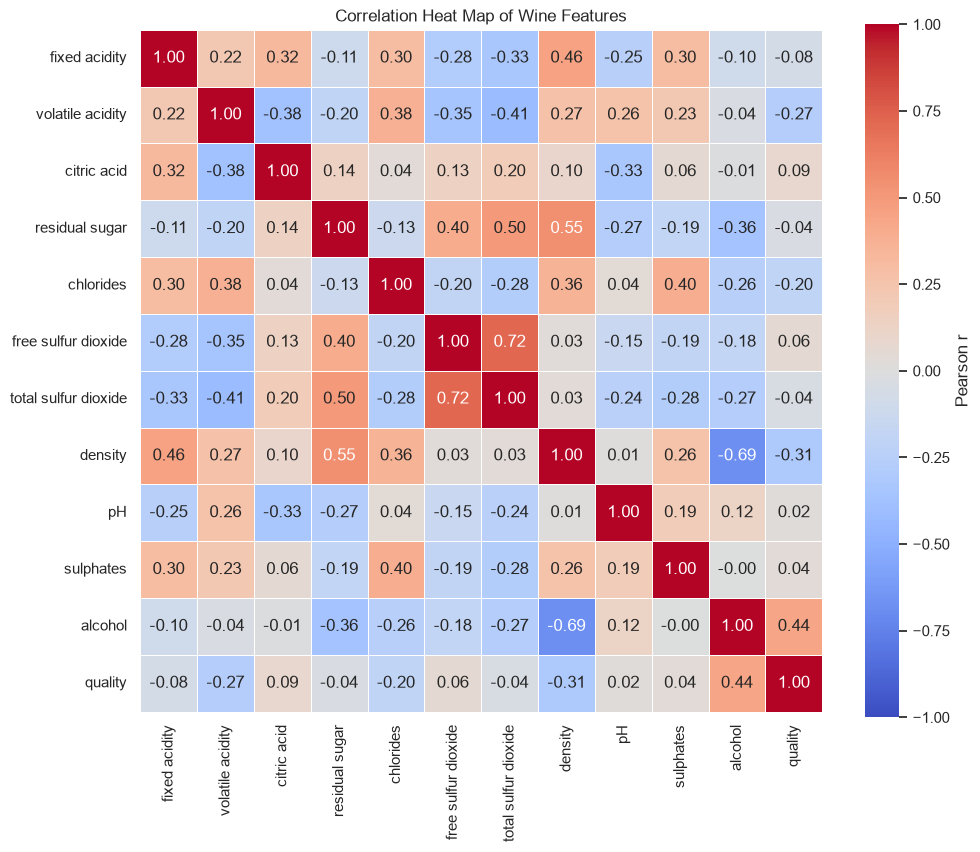

In [11]:
corr = wine.drop(columns="type").corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation Heat Map of Wine Features")
save(fig, "05_correlation_heatmap")
plt.show()

## 6. Horizontal Bar Chart — Feature correlation with quality (Matplotlib)
A focused view of the last heat-map row: which features move with quality, and in which direction.

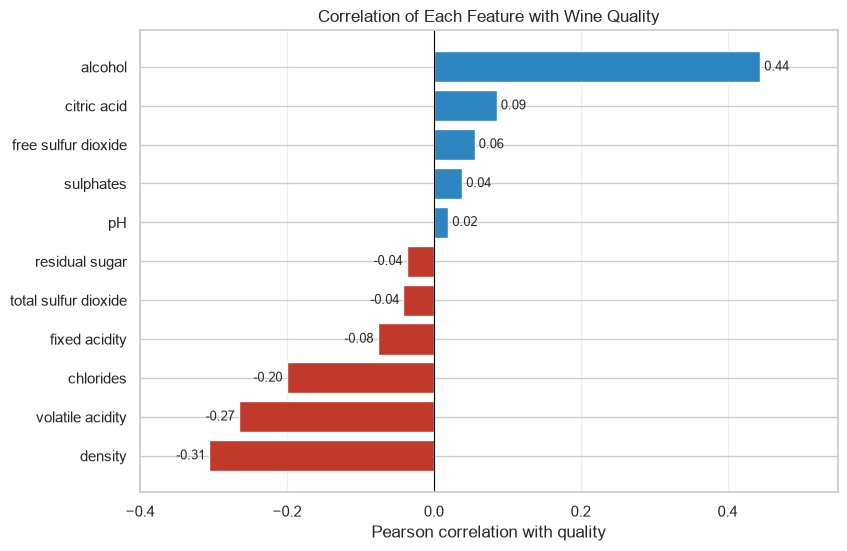

In [12]:
q_corr = corr["quality"].drop("quality").sort_values()
colors = ["#c0392b" if v < 0 else "#2e86c1" for v in q_corr]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(q_corr.index, q_corr.values, color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlation of Each Feature with Wine Quality")
ax.set_xlabel("Pearson correlation with quality")
ax.set_xlim(-0.4, 0.55)
ax.grid(axis="x", alpha=0.3)
save(fig, "06_feature_quality_correlation_bar")
plt.show()

## 7. Violin Plot — Volatile acidity by wine type (Seaborn)
**Distribution comparison.** Red wines have markedly higher and more spread-out volatile acidity than white wines.

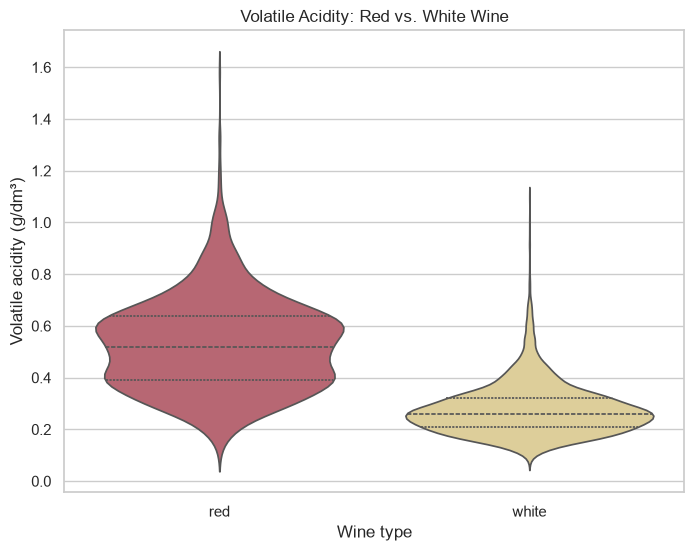

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.violinplot(data=wine, x="type", y="volatile acidity", hue="type",
               palette={"red": "#c45a6a", "white": "#e8d48f"}, inner="quartile", ax=ax)
ax.set_title("Volatile Acidity: Red vs. White Wine")
ax.set_xlabel("Wine type")
ax.set_ylabel("Volatile acidity (g/dm³)")
save(fig, "07_volatile_acidity_violin")
plt.show()

## 8. Line Plot — Average alcohol and volatile acidity per quality score (Matplotlib)
**Trend.** Grouping wines by quality and plotting the mean of each feature shows the trend directly:
from quality 5 upward, mean alcohol climbs steeply for both types. Mean volatile acidity falls steadily for
red wines, while for white wines it stays low and nearly flat.

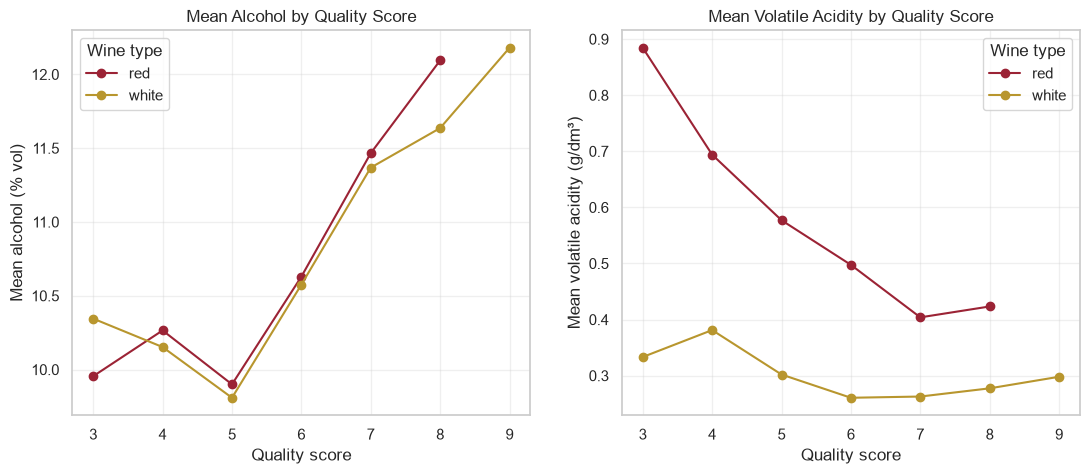

In [14]:
trend = wine.groupby(["type", "quality"])[["alcohol", "volatile acidity"]].mean().reset_index()
line_colors = {"red": "#9b2335", "white": "#b8962e"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for wtype, grp in trend.groupby("type"):
    ax1.plot(grp["quality"], grp["alcohol"], marker="o", color=line_colors[wtype], label=wtype)
    ax2.plot(grp["quality"], grp["volatile acidity"], marker="o", color=line_colors[wtype], label=wtype)

ax1.set_title("Mean Alcohol by Quality Score")
ax1.set_xlabel("Quality score")
ax1.set_ylabel("Mean alcohol (% vol)")
ax2.set_title("Mean Volatile Acidity by Quality Score")
ax2.set_xlabel("Quality score")
ax2.set_ylabel("Mean volatile acidity (g/dm³)")
for ax in (ax1, ax2):
    ax.set_xticks(range(3, 10))
    ax.grid(True, alpha=0.3)
    ax.legend(title="Wine type")
save(fig, "08_mean_by_quality_line")
plt.show()

## 9. Pair Plot — Pairwise relationships of key features (Seaborn)
**Multivariate.** Scatter plots for every pair of the most quality-related features, with each feature's
distribution on the diagonal. Red and white wines separate clearly on volatile acidity and total sulfur dioxide.

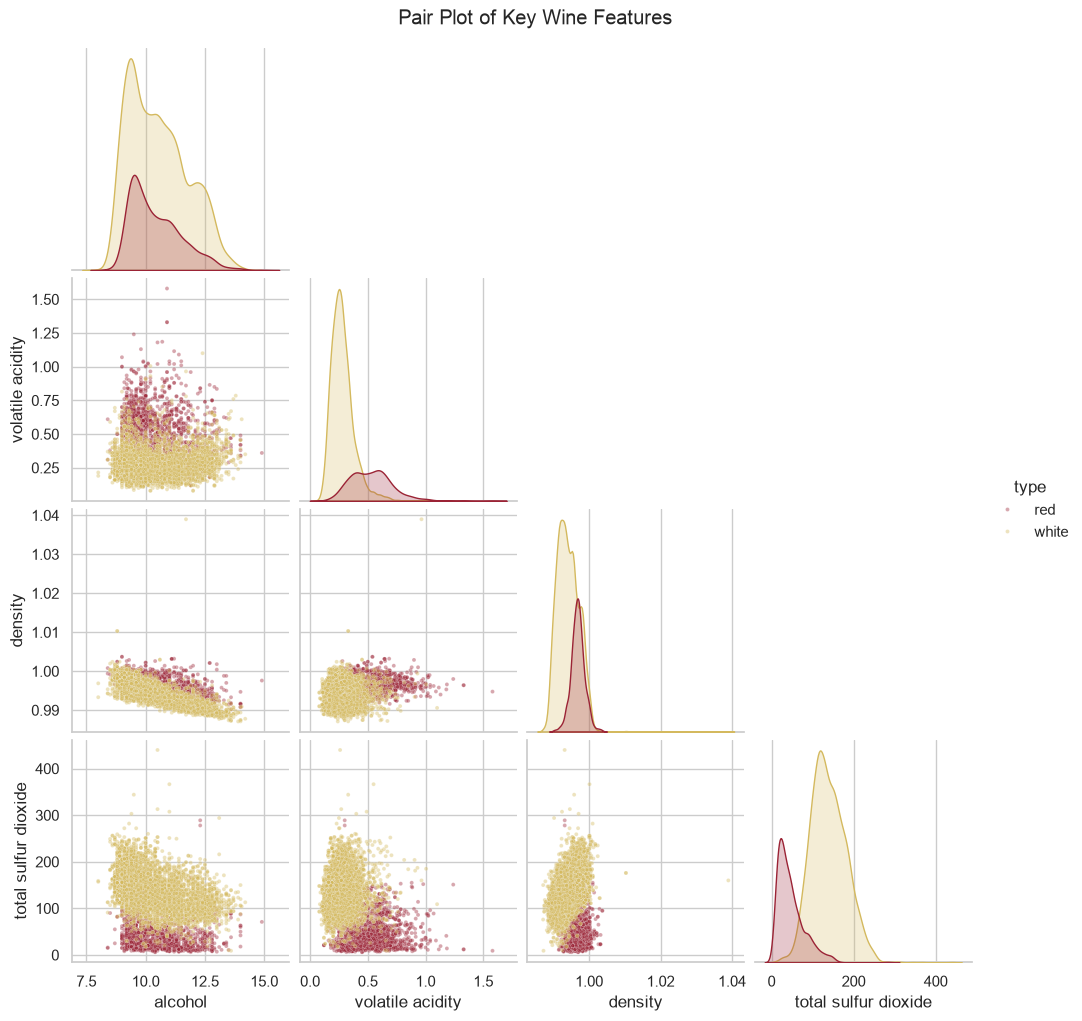

In [15]:
pair_cols = ["alcohol", "volatile acidity", "density", "total sulfur dioxide", "type"]
g = sns.pairplot(wine[pair_cols], hue="type", corner=True,
                 palette={"red": "#9b2335", "white": "#d4b95e"},
                 plot_kws={"s": 8, "alpha": 0.4})
g.figure.suptitle("Pair Plot of Key Wine Features", y=1.02)
save(g.figure, "09_key_features_pairplot")
plt.show()

## 10. Swarm Plot + Box Plot — Sulphates by quality, red wines (Seaborn)
**Distribution with individual points.** The box shows the summary statistics; the swarm shows every wine.
A random sample of 400 red wines keeps the swarm readable. Better-rated red wines tend to have more sulphates.

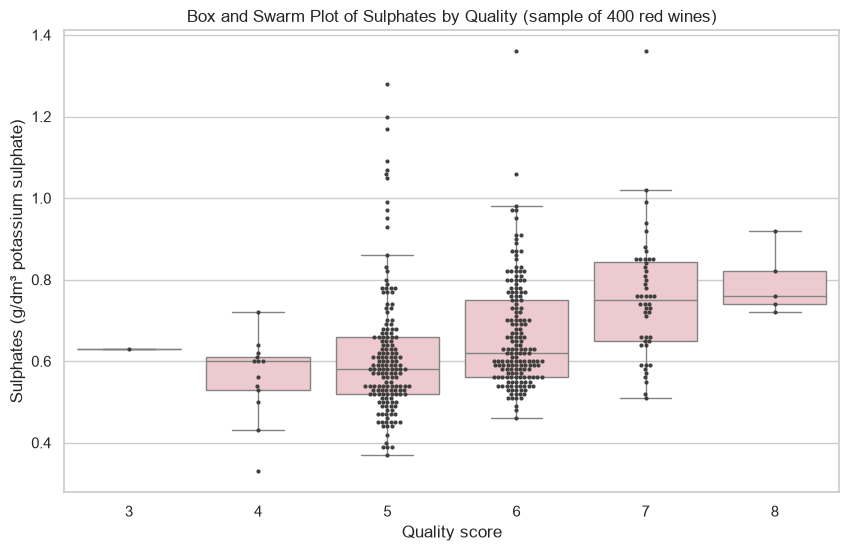

In [16]:
red_sample = wine[wine["type"] == "red"].sample(400, random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=red_sample, x="quality", y="sulphates", color="#f2c4cb",
            showfliers=False, ax=ax)
sns.swarmplot(data=red_sample, x="quality", y="sulphates", color=".25", size=3, ax=ax)
ax.set_title("Box and Swarm Plot of Sulphates by Quality (sample of 400 red wines)")
ax.set_xlabel("Quality score")
ax.set_ylabel("Sulphates (g/dm³ potassium sulphate)")
save(fig, "10_sulphates_box_swarm")
plt.show()

## Key Findings
1. **Quality is imbalanced** — ~77% of wines score 5 or 6.
2. **Alcohol** is the strongest positive correlate of quality (r ≈ 0.44).
3. **Volatile acidity** and **density** are the strongest negative correlates.
4. **Red and white wines differ chemically** — red wines have much higher volatile acidity, while white wines have more residual sugar and sulfur dioxide.

## Best practices applied
- Every chart has a title and labelled axes with units.
- Consistent colour mapping (red / white) across charts; diverging palette centred at 0 for correlations.
- `common_norm=False` / density scaling so the smaller red-wine sample is comparable to white.